# __Inteligencia Artificial - IUA 2026__

### *Exploración y Análisis del Dataset*

### Integrantes
* **Celeste Antonella Badami** — cbadami845@alumnos.iua.edu.ar
* **Benjamin Vargas** — bvargas161@alumnos.iua.edu.ar

---


## 1. Introducción
Este documento analiza el dataset de métricas con el fin de evaluar la calidad de los datos y definir las decisiones de diseño para el análisis exploratorio (EDA) y la ingeniería de features del modelo de ETA.

## 2. Preparación del entorno

In [2]:
# importación de librerias
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [3]:
# Carga de la muestra de datos preeliminar
df = pd.read_csv('../data/dataset.csv')

### 2.1 Conversiones de datos en dataset

In [4]:
# Convertir a datetime (utc=True maneja automáticamente el +00)
df['date_time'] = pd.to_datetime(df['date_time'], utc=True)

## 3. Análisis Univariado

In [5]:
# Cabecera de la muestra de datos
df.head()

,id,bearing,current_status,direction_id,occupancy_status,latitude,longitude,bus_id,route_id,route_pattern_id,...,precipitation,relative_humidity_2m,weather_code,is_day,current_speed,free_flow_speed,current_travel_time,freeflow_travel_time,confidence,road_closure
0,1,315.0,IN_TRANSIT_TO,0,FULL,42.359920,-71.094600,y1923,1,1-_-0,...,0.0,65.0,2.0,True,18,18,216,216,1.0,False
1,2,113.0,IN_TRANSIT_TO,1,MANY_SEATS_AVAILABLE,42.371286,-71.116519,y1918,1,1-_-1,...,0.0,63.0,2.0,True,18,18,125,125,1.0,False
2,3,43.0,IN_TRANSIT_TO,1,MANY_SEATS_AVAILABLE,42.349551,-71.088831,y1878,1,1-_-1,...,0.0,63.0,2.0,True,27,33,129,105,1.0,False
3,4,135.0,IN_TRANSIT_TO,1,MANY_SEATS_AVAILABLE,42.342210,-71.084290,y1831,1,1-_-1,...,0.0,65.0,2.0,True,12,15,105,84,1.0,False
4,5,145.0,STOPPED_AT,1,MANY_SEATS_AVAILABLE,42.339168,-71.080314,y1830,1,1-_-1,...,0.0,65.0,2.0,True,17,19,252,225,1.0,False


In [6]:
# Información general
df.info(verbose=True)

<class 'pandas.DataFrame'>
RangeIndex: 11883 entries, 0 to 11882
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype              
---  ------                 --------------  -----              
 0   id                     11883 non-null  int64              
 1   bearing                9371 non-null   float64            
 2   current_status         11883 non-null  str                
 3   direction_id           11883 non-null  int64              
 4   occupancy_status       11755 non-null  str                
 5   latitude               11883 non-null  float64            
 6   longitude              11883 non-null  float64            
 7   bus_id                 11883 non-null  str                
 8   route_id               11883 non-null  int64              
 9   route_pattern_id       11883 non-null  str                
 10  shape_id               11883 non-null  int64              
 11  agency_id              11883 non-null  int64              
 12  l

### 3.1 Valores Nulos

Se verifica que las variables fundamentales para la geolocalización y temporalidad (latitude, longitude, date_time) no presentan valores faltantes. De igual forma, las métricas de tránsito se encuentran completas. Por el contrario, existen registros nulos en algunas variables meteorológicas secundarias y, principalmente, en la columna bearing (dirección en grados del vehículo), la cual concentra la mayor cantidad de datos faltantes.

In [7]:
# Analisis de faltantes/ nulos

# Crear un DataFrame con el análisis de nulos
vacios_summary = pd.DataFrame({
    'Tipo_Dato': df.dtypes,
    'Valores_Vacios': df.isnull().sum(),
    'Valores_Validos': df.notnull().sum(),
    'Porcentaje_Vacio (%)': (df.isnull().sum() / len(df) * 100).round(2)
})

# Filtrar solo las columnas que tienen al menos un valor vacío y ordenar de mayor a menor
vacios_detallados = vacios_summary[vacios_summary['Valores_Vacios'] > 0].sort_values(
    by='Valores_Vacios', ascending=False
)

vacios_detallados

,Tipo_Dato,Valores_Vacios,Valores_Validos,Porcentaje_Vacio (%)
bearing,float64,2512,9371,21.14
occupancy_status,str,128,11755,1.08
temperature_2m,float64,5,11878,0.04
precipitation,float64,5,11878,0.04
relative_humidity_2m,float64,5,11878,0.04
weather_code,float64,5,11878,0.04
is_day,object,5,11878,0.04


Esta tabla nos muestra que muy pocas son las perdidas de datos en terminos de porcentaje (<1%)

Bearing tiene tambien un porcentaje porcentual bajo de perdida

### 3.2 Análisis de ruta

#### 3.2.1 La Flag "*es_desvio*"

![Vehiculo desviado](../images/desvio.jpeg)

El bot cosechador de datos incluía una funcionalidad para calcular la distancia entre el vehículo y la traza del tramo. Se estableció un umbral máximo de 70 metros para determinar cuándo el vehículo se ha desviado del trayecto. Dado que las desviaciones puntuales (como paradas intermedias) no son constantes y representan outliers o valores atípicos en este dominio, es necesario procesar y filtrar dichos registros para evitar distorsionar las métricas y la estimación en tiempo real.

In [8]:
total_filas = len(df)
filas_desviadas = (df['es_desvio'] == 1).sum()
porcentaje_desvio = (filas_desviadas / total_filas) * 100

print(f"Total de registros: {total_filas}")
print(f"Registros con desvío: {filas_desviadas}")
print(f"Porcentaje de desvíos: {porcentaje_desvio:.2f}%")

Total de registros: 11883
Registros con desvío: 609
Porcentaje de desvíos: 5.12%


El bajo porcentaje de desvíos registrado confirma una alta adherencia de los vehículos a la traza oficial, lo que ratifica la utilidad y calidad de la gran mayoría de los datos para el entrenamiento del modelo.

#### 3.2.2 Estatus posibles (*"current_status"*)

Se busca determinar los valores posibles para la feature de *current_status*

In [9]:
# Cantidad de valores únicos en una columna
df['current_status'].unique()

<StringArray>
['IN_TRANSIT_TO', 'STOPPED_AT']
Length: 2, dtype: str

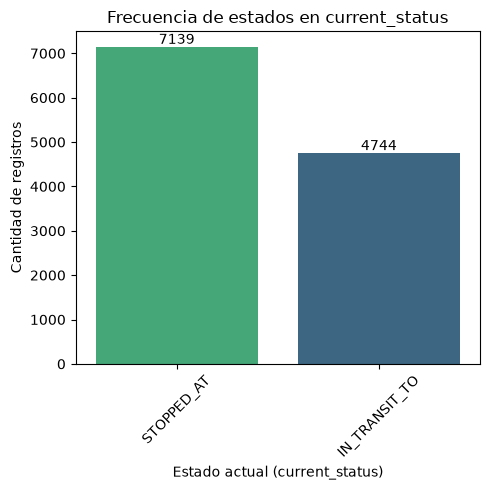

In [10]:
# Analisis de frecuencia de ambas

plt.figure(figsize=(5,5 ))

# Dibujar las barras en el lienzo
ax = sns.countplot(
    data=df,
    x='current_status',
    hue='current_status',                             # Define la variable de color
    order=df['current_status'].value_counts().index,  # Ordena de mayor a menor
    palette='viridis',
    legend=False                                      # Oculta la leyenda innecesaria
)

# Añadir las etiquetas numéricas sobre cada barra
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])


# Personalizar títulos, ejes y muestra la figura
plt.title('Frecuencia de estados en current_status')
plt.xlabel('Estado actual (current_status)')
plt.ylabel('Cantidad de registros')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Se observa mayor tiempo de los colectivos detenidos, esto puede indicar mucho tiempo en las estaciones, o muchas paradas en el camino de ambas direcciones.

#### 3.2.3 Sentido de trayecto (direction_id)

La direccion varia entre 1 y 0 *Harvard Square - Nubian Station*:

- __1__ indica el sentido de *INBOUND* (Hacia el sur, sentido de vuelta)
- __0__ indica el sentido de *OUTBOUND* (Hacia el norte, sentido de ida a Harvard)

Se intenta determinar la cantidad de viajes capturados en cada sentido

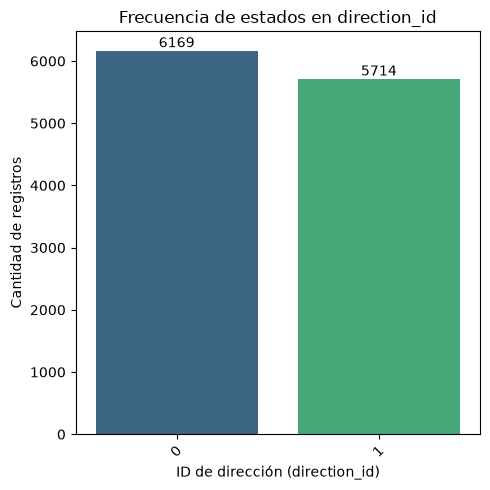

In [11]:
plt.figure(figsize=(5,5 ))

# Dibujar las barras en el lienzo
ax = sns.countplot(
    data=df,
    x='direction_id',
    hue='direction_id',                             # Define la variable de color
    order=df['direction_id'].value_counts().index,  # Ordena de mayor a menor
    palette='viridis',
    legend=False                                      # Oculta la leyenda innecesaria
)

# Añadir las etiquetas numéricas sobre cada barra
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])


# Personalizar títulos, ejes y muestra la figura
plt.title('Frecuencia de estados en direction_id')
plt.xlabel('ID de dirección (direction_id)')
plt.ylabel('Cantidad de registros')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Se observa una cantidad balanceada casi equivalente de registros en ambos sentidos. Puede indicar que los viajes de ida tambien hacen la vuelta.

#### 3.2.4 Estado de ocupacion (ocupanncy_status)

Estados posibles para un bus:

In [12]:
df['occupancy_status'].unique()

<StringArray>
['FULL', 'MANY_SEATS_AVAILABLE', 'FEW_SEATS_AVAILABLE', nan]
Length: 4, dtype: str

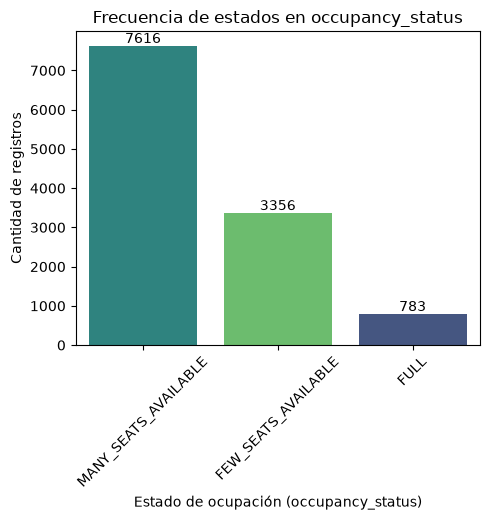

In [13]:
plt.figure(figsize=(5,5.3 ))

# Dibujar las barras en el lienzo
ax = sns.countplot(
    data=df,
    x='occupancy_status',
    hue='occupancy_status',                             # Define la variable de color
    order=df['occupancy_status'].value_counts().index,  # Ordena de mayor a menor
    palette='viridis',
    legend=False                                      # Oculta la leyenda innecesaria
)

# Añadir las etiquetas numéricas sobre cada barra
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])
ax.bar_label(ax.containers[2])


# Personalizar títulos, ejes y muestra la figura
plt.title('Frecuencia de estados en occupancy_status')
plt.xlabel('Estado de ocupación (occupancy_status)')
plt.ylabel('Cantidad de registros')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Se observa una mayor disponibilidad de acientos en la mayoria de las muestras y pocos vehiculos en estado lleno. Lo que puede indicar poco uso del transporte urbano, o un sistema de transporte frecuente por lo que no tiene congestion excesiva

#### 3.2.5 Vehiculos registrados

Cantidad de vehiculos monitoreados (bus_id) unico

In [14]:
df['bus_id'].nunique()

81

Determinar cuantas veces un colectivo el recorrido

In [15]:
# Muestra qué sentidos (0, 1) recorrió cada colectivo y cuántos registros tiene en cada uno
conteo_sentidos = df.groupby(['bus_id', 'direction_id']).size().unstack(fill_value=0)
conteo_sentidos.T

bus_id,y0869,y1726,y1727,y1731,y1734,y1741,y1744,y1745,y1752,y1754,...,y1913,y1916,y1918,y1919,y1920,y1923,y3209,y3273,y3277,y3292
direction_id,,,,,,,,,,,,,,,,,,,,,
0,85,85,58,49,33,23,59,14,69,41,...,88,91,103,23,61,151,63,53,56,46
1,108,88,100,39,30,75,27,65,64,69,...,30,84,112,0,58,116,24,74,53,52


Hay vehiculos que solo se han muestrado en el camino en direccion 1, otros solo la direccion 0, algunos ida y vuelta en forma casi pareja y algunos de forma dispareja

#### 3.2.5 Comportamiento del "bearing" en vehiculos

Analizar que porcentaje se encuentra vacio

In [16]:
vacios = df["bearing"].isnull().sum()
porcentaje = df["bearing"].isnull().mean() * 100

print(f" - Cantidad de vacíos: {vacios:,}")
print(f" - Porcentaje de vacíos: {porcentaje:.2f}%")

 - Cantidad de vacíos: 2,512
 - Porcentaje de vacíos: 21.14%


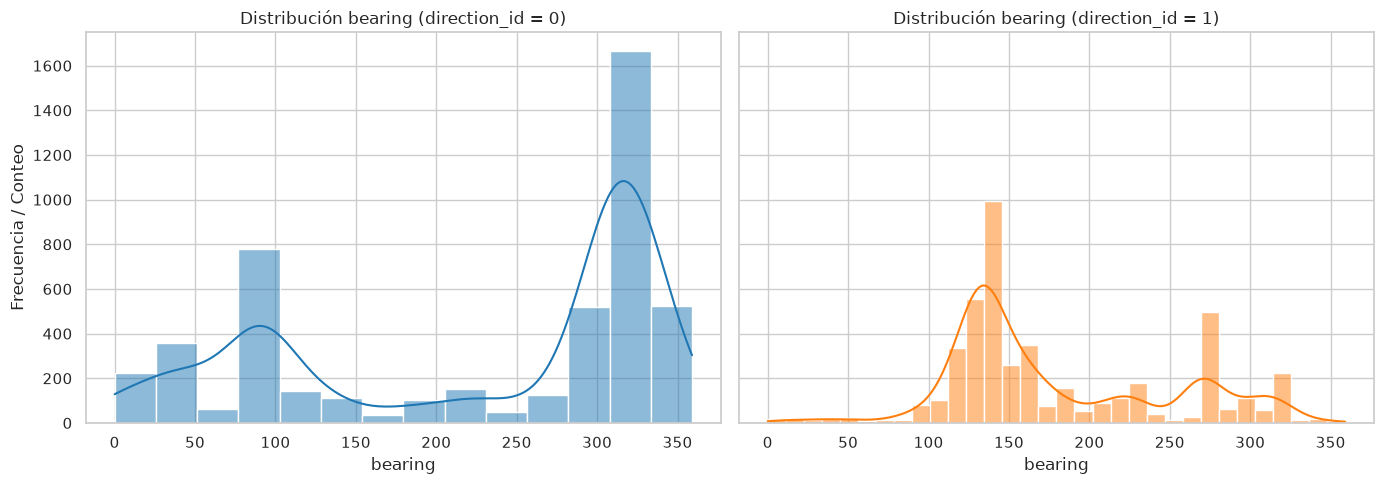

In [32]:
# Configurar estilo visual
sns.set_theme(style="whitegrid")

# Gráficos de Distribución lado a lado (Subplots)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# Sentido 0
sns.histplot(
    data=df[df['direction_id'] == 0],
    x="bearing",
    kde=True,
    color='#1f77b4',
    ax=axes[0]
)
axes[0].set_title(f'Distribución {"bearing"} (direction_id = 0)')
axes[0].set_xlabel("bearing")
axes[0].set_ylabel('Frecuencia / Conteo')

# Sentido 1
sns.histplot(
    data=df[df['direction_id'] == 1],
    x="bearing",
    kde=True,
    color='#ff7f0e',
    ax=axes[1]
)
axes[1].set_title(f'Distribución {"bearing"} (direction_id = 1)')
axes[1].set_xlabel("bearing")

plt.tight_layout()
plt.show()

### 3.3 Análisis de tráfico

#### 3.3.1 Confiabilidad de datos

Variable devuelta por la API tomtom que indica que tan fiables son los datos obtenidos en el trayecto

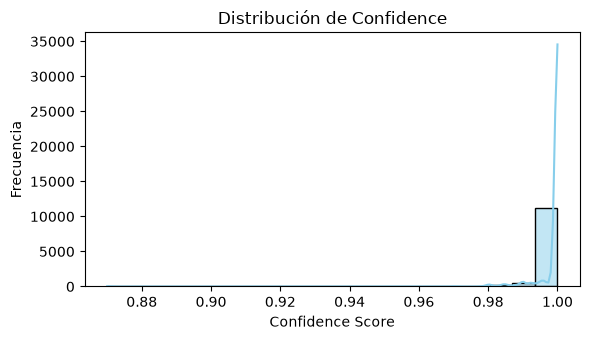

In [17]:
# Configurar un tamaño de gráfico pequeño y estilizado
plt.figure(figsize=(6, 3.5))

# Histograma con curva de densidad (KDE)
sns.histplot(df['confidence'], kde=True, bins=20, color='skyblue')

plt.title('Distribución de Confidence', fontsize=12)
plt.xlabel('Confidence Score')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()

In [18]:
porcentaje_1 = (df['confidence'] == 1).mean() * 100

print(f"Porcentaje de valores igual a 1: {porcentaje_1:.2f}%")

Porcentaje de valores igual a 1: 90.13%


#### 3.3.2 Camino cerrado

/tmp/ipykernel_49164/3422202075.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='road_closure', palette='Blues')


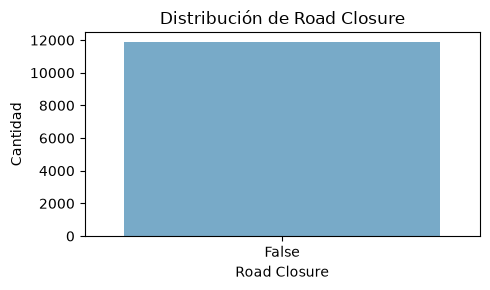

In [19]:
plt.figure(figsize=(5, 3))

# Gráfico de conteo para variables categóricas/booleanas
sns.countplot(data=df, x='road_closure', palette='Blues')

plt.title('Distribución de Road Closure', fontsize=12)
plt.xlabel('Road Closure')
plt.ylabel('Cantidad')
plt.tight_layout()
plt.show()

In [20]:
porcentajes = df['road_closure'].value_counts(normalize=True) * 100
print(porcentajes)

road_closure
False    100.0
Name: proportion, dtype: float64


## 4. Análisis Multivariado

#### 4.1 Dataframes derivados de utilidad

In [21]:
# Crear DataFrame 'viajes' ordenado 
viajes = df.sort_values(
    by=['bus_id', 'direction_id', 'date_time'],
    ascending=[True, True, True]
).reset_index(drop=True).copy()

#### 4.2 Agrupaciones de utilidad

In [22]:
# Calcular deltas de tiempo y distancia en variables locales
delta_tiempo_min = (
    viajes.groupby(['bus_id', 'direction_id'])['date_time']
    .diff()
    .dt.total_seconds() / 60.0
)
delta_distancia = (
    viajes.groupby(['bus_id', 'direction_id'])['distancia_en_traza']
    .diff()
)

# Detectar puntos de corte de viaje (pausa > 15m, reinicio de traza o cambio de grupo)
es_nuevo_viaje = (
    (delta_tiempo_min > 15) | 
    (delta_distancia < -1.0) | 
    (delta_tiempo_min.isna())
)

# Generar ID único incremental directo (1, 2, 3... N)
viajes['trip_id'] = es_nuevo_viaje.cumsum()

viajes.head()

,id,bearing,current_status,direction_id,occupancy_status,latitude,longitude,bus_id,route_id,route_pattern_id,...,relative_humidity_2m,weather_code,is_day,current_speed,free_flow_speed,current_travel_time,freeflow_travel_time,confidence,road_closure,trip_id
0,5728,135.0,STOPPED_AT,0,MANY_SEATS_AVAILABLE,42.329841,-71.083479,y0869,1,1-_-0,...,70.0,0.0,True,18,25,293,211,1.0,False,1
1,5737,61.0,STOPPED_AT,0,MANY_SEATS_AVAILABLE,42.332813,-71.080906,y0869,1,1-_-0,...,70.0,0.0,True,18,25,293,211,1.0,False,1
2,5746,NaN,IN_TRANSIT_TO,0,MANY_SEATS_AVAILABLE,42.331265,-71.077254,y0869,1,1-_-0,...,70.0,1.0,True,18,25,293,211,1.0,False,1
3,5755,45.0,IN_TRANSIT_TO,0,MANY_SEATS_AVAILABLE,42.333249,-71.073838,y0869,1,1-_-0,...,70.0,1.0,True,18,25,293,211,1.0,False,1
4,5764,NaN,STOPPED_AT,0,MANY_SEATS_AVAILABLE,42.333810,-71.073563,y0869,1,1-_-0,...,70.0,1.0,True,18,25,293,211,1.0,False,1


In [23]:
# Agrupar por trip_id y obtener la distancia inicial, final y la recorrida
distancias_recorridas = viajes.groupby('trip_id').agg(
    bus_id=('bus_id', 'first'),
    direction_id=('direction_id', 'first'),
    distancia_inicio=('distancia_en_traza', 'first'),
    distancia_fin=('distancia_en_traza', 'last')
)

# Calcular el recorrido total realizado sobre la traza en ese viaje
distancias_recorridas['distancia_recorrida_total'] = (
    distancias_recorridas['distancia_fin'] - distancias_recorridas['distancia_inicio']
)

distancias_recorridas.head()

,bus_id,direction_id,distancia_inicio,distancia_fin,distancia_recorrida_total
trip_id,,,,,
1,y0869,0,0.037779,1.286737,1.248957
2,y0869,0,0.000000,6.169981,6.169981
3,y0869,0,0.015949,6.989982,6.974034
4,y0869,0,0.020915,6.998855,6.977940
5,y0869,1,0.001763,3.955112,3.953349


#### 4.3 Análisis de viajes

In [24]:
# Cuenta la cantidad total de IDs de viajes únicos
total_viajes = viajes['trip_id'].nunique()
print(f"Total de viajes identificados: {total_viajes}")

Total de viajes identificados: 576


In [25]:
# Agrupar por trip_id y verificar si alguna fila del viaje tuvo desvío
viajes_con_desvio = viajes.groupby('trip_id')['es_desvio'].any()

# Contar la cantidad de viajes únicos que tuvieron al menos un desvío
cantidad_viajes_desviados = viajes_con_desvio.sum()

print(f"Cantidad de viajes con desvío: {cantidad_viajes_desviados}")
print(f"Porcentaje de desvios: {(cantidad_viajes_desviados / total_viajes) * 100:.2f}%")

Cantidad de viajes con desvío: 110
Porcentaje de desvios: 19.10%


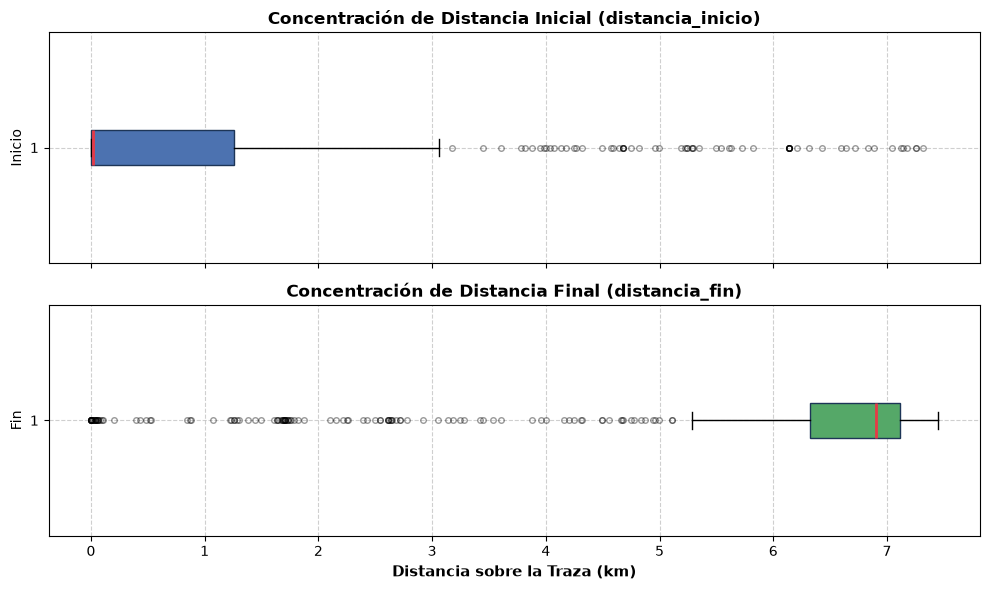

In [26]:
#Crear la figura con 2 subplots compartiendo el mismo eje X
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

# Boxplot para la Distancia de Inicio
ax1.boxplot(
    distancias_recorridas['distancia_inicio'], 
    orientation='horizontal', 
    patch_artist=True,
    boxprops=dict(facecolor='#4C72B0', color='#1D3557'),
    medianprops=dict(color='#E63946', linewidth=2),
    flierprops=dict(marker='o', markersize=4, alpha=0.4)
)
ax1.set_title('Concentración de Distancia Inicial (distancia_inicio)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Inicio')
ax1.grid(True, linestyle='--', alpha=0.6)

# Boxplot para la Distancia Final
ax2.boxplot(
    distancias_recorridas['distancia_fin'], 
    orientation='horizontal', 
    patch_artist=True,
    boxprops=dict(facecolor='#55A868', color='#1D3557'),
    medianprops=dict(color='#E63946', linewidth=2),
    flierprops=dict(marker='o', markersize=4, alpha=0.4)
)
ax2.set_title('Concentración de Distancia Final (distancia_fin)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Distancia sobre la Traza (km)', fontsize=11, fontweight='bold')
ax2.set_ylabel('Fin')
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [27]:
def calcular_outliers_boxplot(df, columna):
    # Calcular Cuartiles (Q1 y Q3) y el IQR
    q1 = df[columna].quantile(0.25)
    q3 = df[columna].quantile(0.75)
    iqr = q3 - q1
    
    # Definir los límites de los bigotes (1.5 * IQR)
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    
    # Filtrar los valores que caen fuera de los bigotes
    es_outlier = (df[columna] < limite_inferior) | (df[columna] > limite_superior)
    df_outliers = df[es_outlier]
    
    cantidad = len(df_outliers)
    porcentaje = (cantidad / len(df)) * 100
    
    return cantidad, porcentaje, limite_inferior, limite_superior, df_outliers

# Ejecución para Distancia de Inicio
cant_inc, pct_inc, min_inc, max_inc, outliers_inc = calcular_outliers_boxplot(distancias_recorridas, 'distancia_inicio')

# Ejecución para Distancia de Fin
cant_fin, pct_fin, min_fin, max_fin, outliers_fin = calcular_outliers_boxplot(distancias_recorridas, 'distancia_fin')

# Mostrar Resultados
print(f"Límites de bigotes: [{min_inc:.3f} km , {max_inc:.3f} km]")
print(f"Cantidad de viajes fuera de bigotes: {cant_inc} ({pct_inc:.2f}%)\n")

print(f"Límites de bigotes: [{min_fin:.3f} km , {max_fin:.3f} km]")
print(f"Cantidad de viajes fuera de bigotes: {cant_fin} ({pct_fin:.2f}%)")

Límites de bigotes: [-1.892 km , 3.153 km]
Cantidad de viajes fuera de bigotes: 64 (11.11%)

Límites de bigotes: [5.129 km , 8.309 km]
Cantidad de viajes fuera de bigotes: 120 (20.83%)


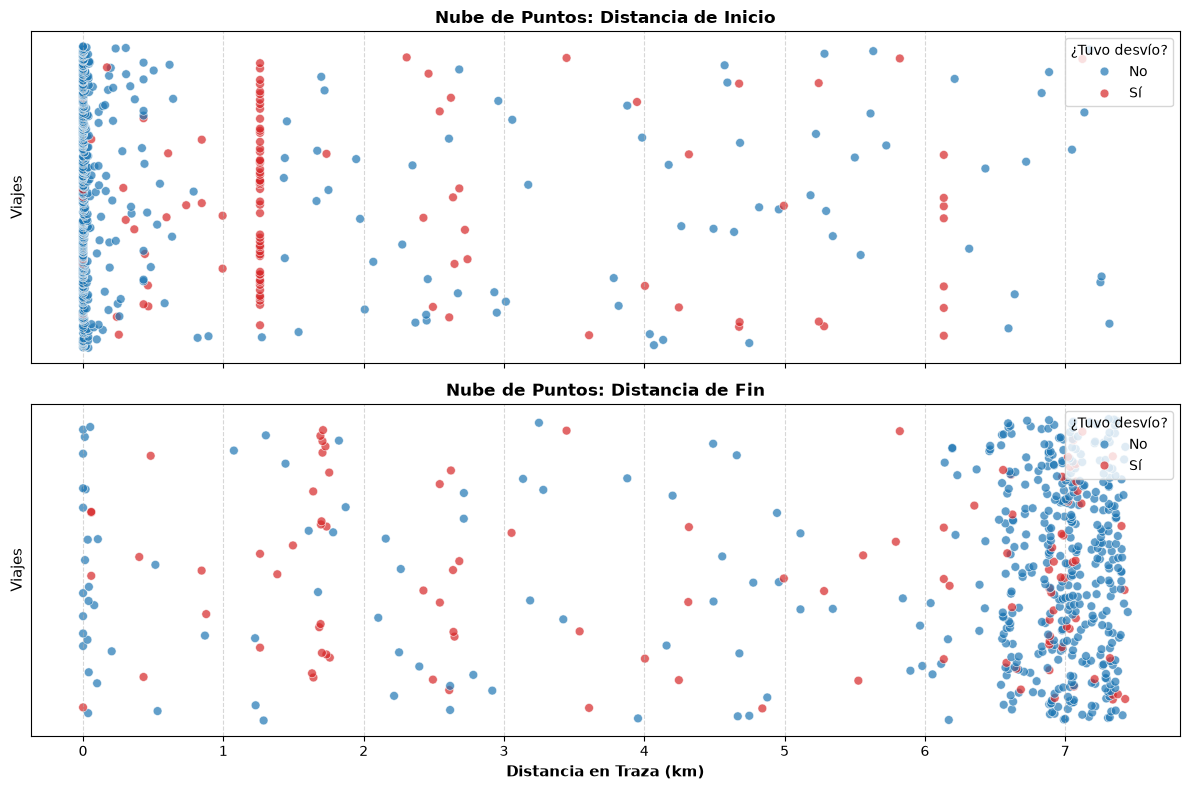

In [28]:
# Consolidar desvío y mapear como etiquetas 'Sí' y 'No'
tiene_desvio = viajes.groupby('trip_id')['es_desvio'].any()
distancias_recorridas['es_desvio_label'] = (
    distancias_recorridas.index.map(tiene_desvio)
    .map({False: 'No', True: 'Sí'})
)

# Configurar la figura (2 subplots compartiendo el eje X)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Paleta asignada explícitamente a las cadenas 'No' y 'Sí'
palette = {'No': '#1F77B4', 'Sí': '#D62728'}

# Scatter plot 1: Distancia de Inicio
sns.scatterplot(
    data=distancias_recorridas,
    x='distancia_inicio',
    y='trip_id',
    hue='es_desvio_label',
    palette=palette,
    alpha=0.7,
    s=40,
    ax=ax1
)
ax1.set_title('Nube de Puntos: Distancia de Inicio', fontsize=12, fontweight='bold')
ax1.set_ylabel('Viajes', fontsize=11)
ax1.set_yticks([])  # Elimina etiquetas del eje Y
ax1.grid(True, linestyle='--', alpha=0.5)

# Scatter plot 2: Distancia de Fin
sns.scatterplot(
    data=distancias_recorridas,
    x='distancia_fin',
    y='trip_id',
    hue='es_desvio_label',
    palette=palette,
    alpha=0.7,
    s=40,
    ax=ax2
)
ax2.set_title('Nube de Puntos: Distancia de Fin', fontsize=12, fontweight='bold')
ax2.set_xlabel('Distancia en Traza (km)', fontsize=11, fontweight='bold')
ax2.set_ylabel('Viajes', fontsize=11)
ax2.set_yticks([])  # Elimina etiquetas del eje Y
ax2.grid(True, linestyle='--', alpha=0.5)

#Leyendas personalizadas automáticas según hue
ax1.legend(title='¿Tuvo desvío?', loc='upper right')
ax2.legend(title='¿Tuvo desvío?', loc='upper right')

plt.tight_layout()
plt.show()